Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


High-demand threshold (75th percentile): 23.2000
0 = Normal demand
1 = High demand

Class distribution:
DemandClass
0    54487
1    18356
Name: count, dtype: int64

CLASSIFICATION RESULTS
Accuracy: 0.6663
Precision: 0.3675
Recall: 0.45
F1-score: 0.4046
ROC-AUC: 0.6539

Detailed classification report:
              precision    recall  f1-score   support

           0       0.80      0.74      0.77     10898
           1       0.37      0.45      0.40      3671

    accuracy                           0.67     14569
   macro avg       0.58      0.59      0.59     14569
weighted avg       0.69      0.67      0.68     14569



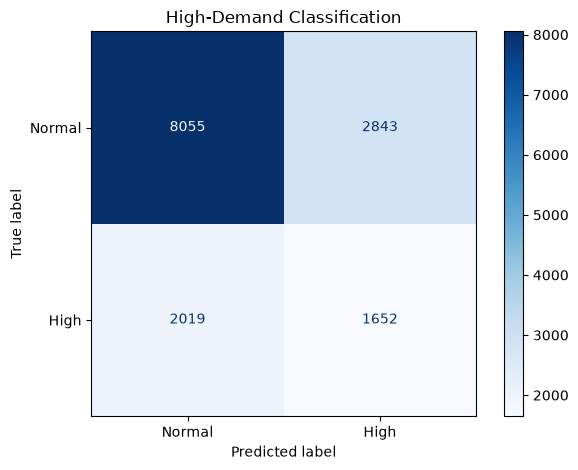


Classification completed!
Saved model: c:\Users\Shyamsekar\OneDrive\Desktop\EV_Charging_Demand_Project\models\best_classification_model.joblib
Saved metrics: c:\Users\Shyamsekar\OneDrive\Desktop\EV_Charging_Demand_Project\models\classification_results.csv


In [1]:

# ============================================================
# FILE 3: EV CHARGING DEMAND CLASSIFICATION
# ============================================================

%pip install pandas numpy matplotlib scikit-learn joblib

# STEP 1: IMPORT LIBRARIES
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
)

# STEP 2: FIND PROJECT FOLDER
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "cleaned_charging_data.csv"
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# STEP 3: LOAD DATA
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Run File 1 first."
    )

df = pd.read_csv(DATA_PATH)

if "Demand" not in df.columns:
    raise ValueError("The dataset must contain a Demand column.")

df["Demand"] = pd.to_numeric(df["Demand"], errors="coerce")
df = df.dropna(subset=["Demand"]).copy()

# STEP 4: CREATE HIGH/NORMAL DEMAND LABELS
threshold = df["Demand"].quantile(0.75)

df["DemandClass"] = (
    df["Demand"] >= threshold
).astype(int)

print(f"High-demand threshold (75th percentile): {threshold:.4f}")
print("0 = Normal demand")
print("1 = High demand")
print("\nClass distribution:")
print(df["DemandClass"].value_counts())

# STEP 5: SELECT FEATURES
candidate_features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Hour",
    "Day",
    "Month",
    "DayOfWeek",
    "IsWeekend",
    "TimeOfDay",
]

features = [c for c in candidate_features if c in df.columns]

if not features:
    raise ValueError(
        "No expected feature columns found. "
        "Check the dataset's actual column names."
    )

X = df[features].copy()
y = df["DemandClass"]

numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    c for c in X.columns if c not in numeric_features
]

# STEP 6: PREPROCESS DATA
transformers = []

if numeric_features:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

# STEP 7: SPLIT DATA
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# STEP 8: TRAIN CLASSIFIER
classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1,
    )),
])

classifier.fit(X_train, y_train)

# STEP 9: PREDICT
y_pred = classifier.predict(X_test)
y_prob = classifier.predict_proba(X_test)[:, 1]

# STEP 10: EVALUATE
print("\nCLASSIFICATION RESULTS")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# STEP 11: CONFUSION MATRIX
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Normal", "High"],
    cmap="Blues",
)

plt.title("High-Demand Classification")
plt.tight_layout()
plt.show()

# STEP 12: SAVE MODEL AND RESULTS
joblib.dump(
    classifier,
    MODEL_DIR / "best_classification_model.joblib",
)

metrics = {
    "Threshold_75th_percentile": threshold,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
}

if len(np.unique(y_test)) == 2:
    metrics["ROC_AUC"] = roc_auc_score(y_test, y_prob)

pd.DataFrame([metrics]).to_csv(
    MODEL_DIR / "classification_results.csv",
    index=False,
)

print("\nClassification completed!")
print("Saved model:", MODEL_DIR / "best_classification_model.joblib")
print("Saved metrics:", MODEL_DIR / "classification_results.csv")
